SCRIPT TABAJO DE INVESTIGACIÓN 2

    QUINTANA QUISPE JOSE ORLANDO 

In [43]:
"""
================================================================================
SCRIPT 0: ANÁLISIS DIAGNÓSTICO DE DATASET INICIALES
Ingeniería de Minas
Análisis de calidad, duplicados y emparejamiento de códigos
================================================================================
"""
import pandas as pd
import numpy as np
from collections import Counter

print("="*80)
print("ANÁLISIS DIAGNÓSTICO DE DATASETS INICIALES")
print("="*80)

# ==============================================================================
# PASO 1: CARGA DE DATASETS
# ==============================================================================
print("\n[1/7] Cargando datasets...")

# Dataset académico
df_academico = pd.read_csv('MINAS_2020_2025_AGGREGATED123.csv')
print(f"✅ Dataset académico cargado: {df_academico.shape[0]:,} filas × {df_academico.shape[1]} columnas")

# Dataset socioeconómico
df_socioeconomico = pd.read_csv(
    'reporte Socioeconomico - FICHAS 20201 AL 20252 ING MINAS ACT1123.csv',
    encoding='cp1252'
)
print(f"✅ Dataset socioeconómico cargado: {df_socioeconomico.shape[0]:,} filas × {df_socioeconomico.shape[1]} columnas")


ANÁLISIS DIAGNÓSTICO DE DATASETS INICIALES

[1/7] Cargando datasets...
✅ Dataset académico cargado: 840 filas × 18 columnas
✅ Dataset socioeconómico cargado: 3,902 filas × 106 columnas


In [44]:

# ==============================================================================
# PASO 2: ANÁLISIS DE CÓDIGOS DE ESTUDIANTE
# ==============================================================================
print("\n[2/7] Analizando códigos de estudiante...")

# Verificar columnas de código
print(f"\n📋 Columnas en dataset académico:")
print(df_academico.columns.tolist()[:5])

print(f"\n📋 Columnas en dataset socioeconómico:")
print(df_socioeconomico.columns.tolist()[:5])

# Extraer códigos (asumiendo que la primera columna es el código)
codigos_academico = df_academico.iloc[:, 0].astype(str).str.strip()
codigos_socioeconomico = df_socioeconomico.iloc[:, 0].astype(str).str.strip()

print(f"\n📊 Total de códigos en dataset académico: {len(codigos_academico):,}")
print(f"📊 Total de códigos en dataset socioeconómico: {len(codigos_socioeconomico):,}")



[2/7] Analizando códigos de estudiante...

📋 Columnas en dataset académico:
['CODESTUDIANTE', 'ESCUELA', 'CLASIFICACION_ACTUAL', 'MODALIDAD_INGRESO', 'SEMESTRE_INGRESO']

📋 Columnas en dataset socioeconómico:
['CODESTUDIANTE', 'SEMESTRE', 'SEXO', 'ESTADO_CIVIL', 'NRO_HIJOS']

📊 Total de códigos en dataset académico: 840
📊 Total de códigos en dataset socioeconómico: 3,902


In [45]:

# ==============================================================================
# PASO 3: DETECCIÓN DE CÓDIGOS DUPLICADOS
# ==============================================================================
print("\n[3/7] Detectando códigos duplicados...")

# Dataset académico
duplicados_academico = codigos_academico[codigos_academico.duplicated()]
conteo_duplicados_academico = Counter(duplicados_academico)
total_duplicados_academico = len(duplicados_academico)

print(f"\n📊 Dataset Académico:")
print(f"   • Códigos únicos: {codigos_academico.nunique():,}")
print(f"   • Códigos duplicados: {total_duplicados_academico:,}")
print(f"   • Porcentaje de duplicados: {(total_duplicados_academico/len(codigos_academico))*100:.2f}%")

if total_duplicados_academico > 0:
    print(f"\n   Top 10 códigos más duplicados:")
    for codigo, count in sorted(conteo_duplicados_academico.items(), key=lambda x: x[1], reverse=True)[:10]:
        print(f"      - {codigo}: {count} veces")

# Dataset socioeconómico
duplicados_socioeconomico = codigos_socioeconomico[codigos_socioeconomico.duplicated()]
conteo_duplicados_socioeconomico = Counter(duplicados_socioeconomico)
total_duplicados_socioeconomico = len(duplicados_socioeconomico)

print(f"\n Dataset Socioeconómico:")
print(f"   • Códigos únicos: {codigos_socioeconomico.nunique():,}")
print(f"   • Códigos duplicados: {total_duplicados_socioeconomico:,}")
print(f"   • Porcentaje de duplicados: {(total_duplicados_socioeconomico/len(codigos_socioeconomico))*100:.2f}%")

if total_duplicados_socioeconomico > 0:
    print(f"\n   Top 10 códigos más duplicados:")
    for codigo, count in sorted(conteo_duplicados_socioeconomico.items(), key=lambda x: x[1], reverse=True)[:10]:
        print(f"      - {codigo}: {count} veces")


[3/7] Detectando códigos duplicados...

📊 Dataset Académico:
   • Códigos únicos: 840
   • Códigos duplicados: 0
   • Porcentaje de duplicados: 0.00%

 Dataset Socioeconómico:
   • Códigos únicos: 862
   • Códigos duplicados: 3,040
   • Porcentaje de duplicados: 77.91%

   Top 10 códigos más duplicados:
      - 2021303005: 8 veces
      - 2020103067: 8 veces
      - 2019103101: 8 veces
      - 2020103012: 8 veces
      - 2017303002: 8 veces
      - 2017103003: 8 veces
      - 2021103084: 8 veces
      - 2020103081: 8 veces
      - 2021103032: 8 veces
      - 2019103102: 8 veces


In [46]:
# ==============================================================================
# PASO 4: ANÁLISIS DE EMPAREJAMIENTO (JOIN)
# ==============================================================================
print("\n[4/7] Analizando emparejamiento de códigos...")

# Convertir a sets para operaciones de conjuntos
set_academico = set(codigos_academico)
set_socioeconomico = set(codigos_socioeconomico)

# Códigos en ambos datasets (intersección)
codigos_comunes = set_academico.intersection(set_socioeconomico)
print(f"\n✅ Códigos en AMBOS datasets (emparejables): {len(codigos_comunes):,}")
print(f"   • Porcentaje del dataset académico: {(len(codigos_comunes)/len(set_academico))*100:.2f}%")
print(f"   • Porcentaje del dataset socioeconómico: {(len(codigos_comunes)/len(set_socioeconomico))*100:.2f}%")

# Códigos solo en dataset académico
solo_academico = set_academico - set_socioeconomico
print(f"\n⚠️ Códigos SOLO en dataset académico: {len(solo_academico):,}")
print(f"   • Porcentaje: {(len(solo_academico)/len(set_academico))*100:.2f}%")

# Códigos solo en dataset socioeconómico
solo_socioeconomico = set_socioeconomico - set_academico
print(f"\n⚠️ Códigos SOLO en dataset socioeconómico: {len(solo_socioeconomico):,}")
print(f"   • Porcentaje: {(len(solo_socioeconomico)/len(set_socioeconomico))*100:.2f}%")

# Unión total de códigos
union_total = set_academico.union(set_socioeconomico)
print(f"\n Total de códigos únicos (unión): {len(union_total):,}")



[4/7] Analizando emparejamiento de códigos...

✅ Códigos en AMBOS datasets (emparejables): 833
   • Porcentaje del dataset académico: 99.17%
   • Porcentaje del dataset socioeconómico: 96.64%

⚠️ Códigos SOLO en dataset académico: 7
   • Porcentaje: 0.83%

⚠️ Códigos SOLO en dataset socioeconómico: 29
   • Porcentaje: 3.36%

 Total de códigos únicos (unión): 869


In [47]:

# ==============================================================================
# PASO 5: ANÁLISIS DE CALIDAD DE DATOS
# ==============================================================================
print("\n[5/7] Analizando calidad de datos...")

# Dataset académico
print(f"\n Dataset Académico - Calidad:")
print(f"   • Valores nulos totales: {df_academico.isnull().sum().sum():,}")
print(f"   • Porcentaje de nulos: {(df_academico.isnull().sum().sum()/(df_academico.shape[0]*df_academico.shape[1]))*100:.2f}%")

# Variables críticas
variables_criticas_acad = ['PROMEDIO_PONDERADO_GENERAL', 'CURSOS_APROBADOS', 'CURSOS_DESAPROBADOS']
for var in variables_criticas_acad:
    if var in df_academico.columns:
        nulos = df_academico[var].isnull().sum()
        print(f"   • {var}: {nulos:,} nulos ({(nulos/len(df_academico))*100:.2f}%)")

# Dataset socioeconómico
print(f"\n📊 Dataset Socioeconómico - Calidad:")
print(f"   • Valores nulos totales: {df_socioeconomico.isnull().sum().sum():,}")
print(f"   • Porcentaje de nulos: {(df_socioeconomico.isnull().sum().sum()/(df_socioeconomico.shape[0]*df_socioeconomico.shape[1]))*100:.2f}%")



[5/7] Analizando calidad de datos...

 Dataset Académico - Calidad:
   • Valores nulos totales: 0
   • Porcentaje de nulos: 0.00%
   • PROMEDIO_PONDERADO_GENERAL: 0 nulos (0.00%)
   • CURSOS_APROBADOS: 0 nulos (0.00%)
   • CURSOS_DESAPROBADOS: 0 nulos (0.00%)

📊 Dataset Socioeconómico - Calidad:
   • Valores nulos totales: 4,499
   • Porcentaje de nulos: 1.09%


In [48]:
# ==============================================================================
# PASO 6: ANÁLISIS DE CONSISTENCIA
# ==============================================================================
print("\n[6/7] Analizando consistencia de datos...")

# Verificar rangos válidos en dataset académico
if 'PROMEDIO_PONDERADO_GENERAL' in df_academico.columns:
    promedios = df_academico['PROMEDIO_PONDERADO_GENERAL']
    fuera_rango = promedios[(promedios < 0) | (promedios > 20)]
    print(f"\n Promedios fuera de rango (0-20): {len(fuera_rango):,}")
    if len(fuera_rango) > 0:
        print(f"   • Valores mínimos: {promedios.min():.2f}")
        print(f"   • Valores máximos: {promedios.max():.2f}")

# Verificar consistencia de cursos aprobados/desaprobados
if 'CURSOS_APROBADOS' in df_academico.columns and 'CURSOS_DESAPROBADOS' in df_academico.columns:
    inconsistencias = df_academico[
        (df_academico['CURSOS_APROBADOS'] < 0) | 
        (df_academico['CURSOS_DESAPROBADOS'] < 0)
    ]
    print(f"📊 Registros con valores negativos en cursos: {len(inconsistencias):,}")


[6/7] Analizando consistencia de datos...

 Promedios fuera de rango (0-20): 0
📊 Registros con valores negativos en cursos: 0


In [49]:
# ==============================================================================
# PASO 7: RESUMEN EJECUTIVO
# ==============================================================================
print("\n" + "="*80)
print("RESUMEN EJECUTIVO - ANÁLISIS DIAGNÓSTICO")
print("="*80)

print(f"""
📊 DATASETS INICIALES:
   • Dataset Académico: {df_academico.shape[0]:,} registros × {df_academico.shape[1]} columnas
   • Dataset Socioeconómico: {df_socioeconomico.shape[0]:,} registros × {df_socioeconomico.shape[1]} columnas

🔍 CÓDIGOS DE ESTUDIANTE:
   • Códigos únicos en académico: {codigos_academico.nunique():,}
   • Códigos únicos en socioeconómico: {codigos_socioeconomico.nunique():,}
   • Códigos duplicados en académico: {total_duplicados_academico:,} ({(total_duplicados_academico/len(codigos_academico))*100:.2f}%)
   • Códigos duplicados en socioeconómico: {total_duplicados_socioeconomico:,} ({(total_duplicados_socioeconomico/len(codigos_socioeconomico))*100:.2f}%)

🔗 EMPAREJAMIENTO (JOIN):
   • Códigos en ambos datasets: {len(codigos_comunes):,} ({(len(codigos_comunes)/len(set_academico))*100:.2f}% del académico)
   • Códigos solo en académico: {len(solo_academico):,}
   • Códigos solo en socioeconómico: {len(solo_socioeconomico):,}
   • Total códigos únicos (unión): {len(union_total):,}

️ PROBLEMAS DETECTADOS:
   • Duplicados en dataset académico: {total_duplicados_academico:,} registros
   • Duplicados en dataset socioeconómico: {total_duplicados_socioeconomico:,} registros
   • Registros sin emparejar: {len(solo_academico) + len(solo_socioeconomico):,}

✅ RECOMENDACIONES:
   1. Eliminar duplicados antes del merge
   2. Usar INNER JOIN para garantizar consistencia
   3. Investigar códigos sin emparejar
   4. Validar rangos de variables críticas
""")

# Guardar resumen
resumen = {
    'Metrica': [
        'Registros Académico',
        'Registros Socioeconómico',
        'Códigos Únicos Académico',
        'Códigos Únicos Socioeconómico',
        'Duplicados Académico',
        'Duplicados Socioeconómico',
        'Códigos en Ambos (Emparejables)',
        'Códigos Solo Académico',
        'Códigos Solo Socioeconómico',
        'Total Códigos Únicos'
    ],
    'Valor': [
        len(df_academico),
        len(df_socioeconomico),
        codigos_academico.nunique(),
        codigos_socioeconomico.nunique(),
        total_duplicados_academico,
        total_duplicados_socioeconomico,
        len(codigos_comunes),
        len(solo_academico),
        len(solo_socioeconomico),
        len(union_total)
    ],
    'Porcentaje': [
        '100%',
        '100%',
        f"{(codigos_academico.nunique()/len(df_academico))*100:.2f}%",
        f"{(codigos_socioeconomico.nunique()/len(df_socioeconomico))*100:.2f}%",
        f"{(total_duplicados_academico/len(df_academico))*100:.2f}%",
        f"{(total_duplicados_socioeconomico/len(df_socioeconomico))*100:.2f}%",
        f"{(len(codigos_comunes)/len(set_academico))*100:.2f}% del académico",
        f"{(len(solo_academico)/len(set_academico))*100:.2f}%",
        f"{(len(solo_socioeconomico)/len(set_socioeconomico))*100:.2f}%",
        '-'
    ]
}

df_resumen = pd.DataFrame(resumen)
df_resumen.to_csv('resumen_diagnostico_datasets.csv', index=False)
print("✅ Resumen guardado: resumen_diagnostico_datasets.csv")


RESUMEN EJECUTIVO - ANÁLISIS DIAGNÓSTICO

📊 DATASETS INICIALES:
   • Dataset Académico: 840 registros × 18 columnas
   • Dataset Socioeconómico: 3,902 registros × 106 columnas

🔍 CÓDIGOS DE ESTUDIANTE:
   • Códigos únicos en académico: 840
   • Códigos únicos en socioeconómico: 862
   • Códigos duplicados en académico: 0 (0.00%)
   • Códigos duplicados en socioeconómico: 3,040 (77.91%)

🔗 EMPAREJAMIENTO (JOIN):
   • Códigos en ambos datasets: 833 (99.17% del académico)
   • Códigos solo en académico: 7
   • Códigos solo en socioeconómico: 29
   • Total códigos únicos (unión): 869

️ PROBLEMAS DETECTADOS:
   • Duplicados en dataset académico: 0 registros
   • Duplicados en dataset socioeconómico: 3,040 registros
   • Registros sin emparejar: 36

✅ RECOMENDACIONES:
   1. Eliminar duplicados antes del merge
   2. Usar INNER JOIN para garantizar consistencia
   3. Investigar códigos sin emparejar
   4. Validar rangos de variables críticas

✅ Resumen guardado: resumen_diagnostico_datasets.

In [50]:
"""
================================================================================
SCRIPT 0 v3: FUSIÓN DE DATASETS CON ANÁLISIS DIAGNÓSTICO COMPLETO
Universidad Nacional de Moquegua - Ingeniería de Minas
Periodo: 2020-2025
================================================================================
"""
import pandas as pd
import numpy as np
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("SCRIPT 0 v3: FUSIÓN DE DATASETS CON ANÁLISIS DIAGNÓSTICO")
print("="*80)

# ==============================================================================
# PASO 1: CARGA DE ARCHIVOS CON MANEJO DE BOM
# ==============================================================================
print("\n[1/7] Cargando archivos CSV...")

# Dataset académico
df_academico = pd.read_csv('MINAS_2020_2025_AGGREGATED123.csv')
print(f"✅ Dataset académico: {df_academico.shape[0]:,} filas × {df_academico.shape[1]} columnas")

# Dataset socioeconómico
try:
    df_socioeconomico = pd.read_csv(
        'reporte Socioeconomico - FICHAS 20201 AL 20252 ING MINAS ACT1123.csv',
        encoding='utf-8-sig'
    )
    print("✅ Dataset socioeconómico cargado con utf-8-sig (BOM eliminado)")
except:
    df_socioeconomico = pd.read_csv(
        'reporte Socioeconomico - FICHAS 20201 AL 20252 ING MINAS ACT1123.csv',
        encoding='latin-1'
    )
    df_socioeconomico.columns = [col.replace('ï»¿', '').strip() for col in df_socioeconomico.columns]
    print("✅ Dataset cargado con latin-1 y columnas limpiadas")

print(f"✅ Dataset socioeconómico: {df_socioeconomico.shape[0]:,} filas × {df_socioeconomico.shape[1]} columnas")


SCRIPT 0 v3: FUSIÓN DE DATASETS CON ANÁLISIS DIAGNÓSTICO

[1/7] Cargando archivos CSV...
✅ Dataset académico: 840 filas × 18 columnas
✅ Dataset cargado con latin-1 y columnas limpiadas
✅ Dataset socioeconómico: 3,902 filas × 106 columnas


In [51]:

# ==============================================================================
# PASO 2: ANÁLISIS DE CÓDIGOS Y DUPLICADOS
# ==============================================================================
print("\n[2/7] Analizando códigos de estudiante...")

# Extraer códigos (primera columna)
codigos_academico = df_academico.iloc[:, 0].astype(str).str.strip()
codigos_socioeconomico = df_socioeconomico.iloc[:, 0].astype(str).str.strip()

# Conteo de duplicados
duplicados_academico = codigos_academico[codigos_academico.duplicated()]
duplicados_socioeconomico = codigos_socioeconomico[codigos_socioeconomico.duplicated()]

print(f"\n Dataset Académico:")
print(f"   • Total registros: {len(codigos_academico):,}")
print(f"   • Códigos únicos: {codigos_academico.nunique():,}")
print(f"   • Códigos duplicados: {len(duplicados_academico):,} ({(len(duplicados_academico)/len(codigos_academico))*100:.2f}%)")

print(f"\n📊 Dataset Socioeconómico:")
print(f"   • Total registros: {len(codigos_socioeconomico):,}")
print(f"   • Códigos únicos: {codigos_socioeconomico.nunique():,}")
print(f"   • Códigos duplicados: {len(duplicados_socioeconomico):,} ({(len(duplicados_socioeconomico)/len(codigos_socioeconomico))*100:.2f}%)")



[2/7] Analizando códigos de estudiante...

 Dataset Académico:
   • Total registros: 840
   • Códigos únicos: 840
   • Códigos duplicados: 0 (0.00%)

📊 Dataset Socioeconómico:
   • Total registros: 3,902
   • Códigos únicos: 862
   • Códigos duplicados: 3,040 (77.91%)


In [52]:
# ==============================================================================
# PASO 3: ANÁLISIS DE EMPAREJAMIENTO
# ==============================================================================
print("\n[3/7] Analizando emparejamiento de códigos...")

set_academico = set(codigos_academico)
set_socioeconomico = set(codigos_socioeconomico)

codigos_comunes = set_academico.intersection(set_socioeconomico)
solo_academico = set_academico - set_socioeconomico
solo_socioeconomico = set_socioeconomico - set_academico

print(f"\n EMPAREJAMIENTO:")
print(f"   ✅ Códigos en AMBOS datasets: {len(codigos_comunes):,}")
print(f"      • {len(codigos_comunes)/len(set_academico)*100:.2f}% del dataset académico")
print(f"      • {len(codigos_comunes)/len(set_socioeconomico)*100:.2f}% del dataset socioeconómico")
print(f"\n   ⚠️ Códigos SOLO en académico: {len(solo_academico):,}")
print(f"   ⚠️ Códigos SOLO en socioeconómico: {len(solo_socioeconomico):,}")
print(f"\n   📊 Total códigos únicos (unión): {len(set_academico.union(set_socioeconomico)):,}")
#El pipeline está funcionando perfectamente. 
#Esos 7 estudiantes que se "pierden" son estudiantes que tienen registro académico 
#(notas, cursos, etc.), pero no llenaron o no se procesó su ficha socioeconómica.



[3/7] Analizando emparejamiento de códigos...

 EMPAREJAMIENTO:
   ✅ Códigos en AMBOS datasets: 833
      • 99.17% del dataset académico
      • 96.64% del dataset socioeconómico

   ⚠️ Códigos SOLO en académico: 7
   ⚠️ Códigos SOLO en socioeconómico: 29

   📊 Total códigos únicos (unión): 869


In [53]:
# ==============================================================================
# PASO 4: ELIMINACIÓN DE DUPLICADOS
# ==============================================================================
print("\n[4/7] Eliminando registros duplicados...")

# Guardar conteo antes de eliminar
duplicados_acad_antes = len(duplicados_academico)
duplicados_socio_antes = len(duplicados_socioeconomico)

# Eliminar duplicados manteniendo el primero
df_academico_clean = df_academico.drop_duplicates(subset=df_academico.columns[0], keep='first')
df_socioeconomico_clean = df_socioeconomico.drop_duplicates(subset=df_socioeconomico.columns[0], keep='first')

print(f"   • Dataset académico: {len(df_academico)} → {len(df_academico_clean)} registros")
print(f"   • Dataset socioeconómico: {len(df_socioeconomico)} → {len(df_socioeconomico_clean)} registros")



[4/7] Eliminando registros duplicados...
   • Dataset académico: 840 → 840 registros
   • Dataset socioeconómico: 3902 → 862 registros


In [54]:
# ==============================================================================
# PASO 5: FUSIÓN (INNER JOIN)
# ==============================================================================
print("\n[5/7] Realizando fusión (INNER JOIN)...")

df_fusionado = pd.merge(
    df_academico_clean,
    df_socioeconomico_clean,
    on=df_academico_clean.columns[0],
    how='inner',#<--INNER ESTA ES LA CLAVE
    suffixes=('_acad', '_socio')
)

print(f"\n✅ RESULTADO DE LA FUSIÓN:")
print(f"   • Registros fusionados: {len(df_fusionado):,}")
print(f"   • Columnas totales: {df_fusionado.shape[1]}")
print(f"   • Registros perdidos: {len(df_academico_clean) + len(df_socioeconomico_clean) - len(df_fusionado):,}")



[5/7] Realizando fusión (INNER JOIN)...

✅ RESULTADO DE LA FUSIÓN:
   • Registros fusionados: 833
   • Columnas totales: 123
   • Registros perdidos: 869


In [55]:

# ==============================================================================
# PASO 6: VALIDACIÓN DE CONSISTENCIA
# ==============================================================================
print("\n[6/7] Validando consistencia de datos...")

# Verificar valores nulos
nulos_totales = df_fusionado.isnull().sum().sum()
print(f"   • Valores nulos totales: {nulos_totales:,}")

# Verificar rangos críticos
if 'PROMEDIO_PONDERADO_GENERAL' in df_fusionado.columns:
    promedios = df_fusionado['PROMEDIO_PONDERADO_GENERAL']
    fuera_rango = promedios[(promedios < 0) | (promedios > 20)]
    print(f"   • Promedios fuera de rango (0-20): {len(fuera_rango):,}")


[6/7] Validando consistencia de datos...
   • Valores nulos totales: 671
   • Promedios fuera de rango (0-20): 0


In [56]:
# ==============================================================================
# PASO 7: GUARDADO Y RESUMEN
# ==============================================================================
print("\n[7/7] Guardando dataset fusionado y resumen...")

output_file = 'MINAS_FUSIONADO_COMPLETO.csv'
df_fusionado.to_csv(output_file, index=False, encoding='utf-8')
print(f"✅ Dataset fusionado guardado: {output_file}")

# Guardar resumen diagnóstico
resumen = {
    'Metrica': [
        'Registros Académico Original',
        'Registros Socioeconómico Original',
        'Duplicados Académico',
        'Duplicados Socioeconómico',
        'Códigos Únicos Académico',
        'Códigos Únicos Socioeconómico',
        'Códigos en Ambos (Emparejables)',
        'Códigos Solo Académico',
        'Códigos Solo Socioeconómico',
        'Registros Fusionados Final',
        'Columnas Totales'
    ],
    'Valor': [
        len(df_academico),
        len(df_socioeconomico),
        duplicados_acad_antes,
        duplicados_socio_antes,
        codigos_academico.nunique(),
        codigos_socioeconomico.nunique(),
        len(codigos_comunes),
        len(solo_academico),
        len(solo_socioeconomico),
        len(df_fusionado),
        df_fusionado.shape[1]
    ]
}

df_resumen = pd.DataFrame(resumen)
df_resumen.to_csv('resumen_fusion_v3.csv', index=False)
print("✅ Resumen guardado: resumen_fusion_v3.csv")

print("\n" + "="*80)
print("✅ PROCESO COMPLETADO - SCRIPT 0 v3")
print("="*80)


[7/7] Guardando dataset fusionado y resumen...
✅ Dataset fusionado guardado: MINAS_FUSIONADO_COMPLETO.csv
✅ Resumen guardado: resumen_fusion_v3.csv

✅ PROCESO COMPLETADO - SCRIPT 0 v3


In [57]:
"""
================================================================================
SCRIPT 1 v3: LIMPIEZA, CODIFICACIÓN Y PREPARACIÓN DE DATOS MEJORADA
Universidad Nacional de Moquegua - Ingeniería de Minas
================================================================================
"""
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("SCRIPT 1 v3: LIMPIEZA Y PREPARACIÓN DE DATOS MEJORADA")
print("="*80)

# ==============================================================================
# PASO 1: CARGA ROBUSTA CON MANEJO DE ENCODING
# ==============================================================================
print("\n[1/7] Cargando dataset fusionado...")

archivo_csv = 'MINAS_FUSIONADO_COMPLETO.csv'
codificaciones = ['utf-8', 'latin-1', 'cp1252', 'iso-8859-1']
df = None

for codificacion in codificaciones:
    try:
        df = pd.read_csv(archivo_csv, encoding=codificacion, low_memory=False)
        print(f"✅ Archivo leído con codificación: '{codificacion}'")
        break
    except UnicodeDecodeError:
        print(f"⚠️ Falló con '{codificacion}', intentando siguiente...")

if df is None:
    raise Exception("❌ No se pudo leer el archivo con ninguna codificación")

print(f"📊 Dimensiones originales: {df.shape[0]:,} filas × {df.shape[1]} columnas")


SCRIPT 1 v3: LIMPIEZA Y PREPARACIÓN DE DATOS MEJORADA

[1/7] Cargando dataset fusionado...
✅ Archivo leído con codificación: 'utf-8'
📊 Dimensiones originales: 833 filas × 123 columnas


In [58]:
# ==============================================================================
# PASO 2: CORRECCIÓN DE CARACTERES CORRUPTOS (MOJIBAKE)
# ==============================================================================
print("\n[2/7] Corrigiendo caracteres corruptos y encoding...")

reemplazos_encoding = {
    r'Ã³': 'ó',
    r'ï¿½': 'ó',
    r'Ã±': 'ñ',
    r'ï¿½ï¿½': 'ó',
    r'Ã¡': 'á',
    r'Ã©': 'é',
    r'Ã­': 'í',
    r'Ãº': 'ú'
}

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].replace(reemplazos_encoding, regex=True)

print("✅ Caracteres corruptos corregidos")



[2/7] Corrigiendo caracteres corruptos y encoding...
✅ Caracteres corruptos corregidos


In [59]:
# ==============================================================================
# PASO 3: ELIMINACIÓN DE FILAS NO ESTUDIANTILES
# ==============================================================================
print("\n[3/7] Eliminando filas no estudiantiles...")

primera_col = df.iloc[:, 0].astype(str)
mascara_filtro = ~primera_col.str.contains(
    r'^(Madre|Padre|Solo Padre|Total|piso|pisos|padres|RESUMEN)',
    case=False,
    na=False
)

df = df[mascara_filtro].copy()
print(f"   • Filas eliminadas (no estudiantiles): {(~mascara_filtro).sum():,}")
print(f"   • Filas válidas restantes: {df.shape[0]:,}")



[3/7] Eliminando filas no estudiantiles...
   • Filas eliminadas (no estudiantiles): 0
   • Filas válidas restantes: 833


In [60]:
# ==============================================================================
# PASO 4: LIMPIEZA DE NOMBRES DE COLUMNAS
# ==============================================================================
print("\n[4/7] Limpiando nombres de columnas...")

df.columns = [col.strip() if 'Unnamed' not in str(col) else 'ID_FILA' for col in df.columns]

if 'ID_FILA' in df.columns:
    df = df.drop(columns=['ID_FILA'])

print(f"✅ Total de columnas después de limpieza: {df.shape[1]}")


[4/7] Limpiando nombres de columnas...
✅ Total de columnas después de limpieza: 123


In [61]:
# ==============================================================================
# PASO 5: FEATURE ENGINEERING AVANZADO
# ==============================================================================
print("\n[5/7] Aplicando ingeniería de características avanzada...")

epsilon = 1e-5

# 5.1 Tasa de aprobación
if 'CURSOS_APROBADOS' in df.columns and 'CURSOS_DESAPROBADOS' in df.columns:
    df['TASA_APROBACION'] = df['CURSOS_APROBADOS'] / (
        df['CURSOS_APROBADOS'] + df['CURSOS_DESAPROBADOS'] + epsilon
    )
    print("   ✓ Tasa de aprobación calculada")

# 5.2 Estabilidad académica
if 'PROMEDIO_SEMESTRE_MAX' in df.columns and 'PROMEDIO_SEMESTRE_MIN' in df.columns:
    df['ESTABILIDAD_ACADEMICA'] = df['PROMEDIO_SEMESTRE_MAX'] - df['PROMEDIO_SEMESTRE_MIN']
    print("   ✓ Estabilidad académica calculada")

# 5.3 Ritmo de egreso
if 'CURSOS_APROBADOS' in df.columns and 'SEMESTRES_CURSADOS' in df.columns:
    df['RITMO_EGRESO'] = df['CURSOS_APROBADOS'] / (df['SEMESTRES_CURSADOS'] + epsilon)
    print("   ✓ Ritmo de egreso calculado")

# 5.4 Eficiencia académica (nueva)
if 'CURSOS_UNICOS' in df.columns and 'CURSOS_MATRICULADOS' in df.columns:
    df['EFICIENCIA_ACADEMICA'] = df['CURSOS_UNICOS'] / (df['CURSOS_MATRICULADOS'] + epsilon)
    print("   ✓ Eficiencia académica calculada")

# 5.5 Índice de repetición (nueva)
if 'CURSOS_REPETIDOS_COUNT' in df.columns and 'CURSOS_APROBADOS' in df.columns:
    df['INDICE_REPETICION'] = df['CURSOS_REPETIDOS_COUNT'] / (df['CURSOS_APROBADOS'] + epsilon)
    print("   ✓ Índice de repetición calculado")


[5/7] Aplicando ingeniería de características avanzada...
   ✓ Tasa de aprobación calculada
   ✓ Estabilidad académica calculada
   ✓ Ritmo de egreso calculado
   ✓ Índice de repetición calculado


In [62]:
# ==============================================================================
# PASO 6: ELIMINACIÓN DE COLUMNAS CON DATA LEAKAGE
# ==============================================================================
print("\n[6/7] Eliminando columnas con data leakage e identificadores...")

cols_to_drop = [
    'CODESTUDIANTE', 'CODIGO', 'DNI', 'NOMBRES', 'APE_PAT', 'APE_MAT',
    'PROMEDIOS_POR_SEMESTRE_JSON', 'HISTORIAL_JSON',
    'CODESTUDIANTE_acad', 'CODESTUDIANTE_socio'
]

df = df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors='ignore')
print(f"✅ Dataset limpio: {df.shape[0]:,} filas × {df.shape[1]} columnas")


[6/7] Eliminando columnas con data leakage e identificadores...
✅ Dataset limpio: 833 filas × 125 columnas


In [63]:
# ==============================================================================
# PASO 7: GUARDADO DEL DATASET LIMPIO
# ==============================================================================
print("\n[7/7] Guardando dataset limpio...")

output_file = 'MINAS_LIMPIO_IMPUTADO_RIGUROSO_v3.csv'
df.to_csv(output_file, index=False, encoding='utf-8')

print(f"\n✅ PROCESO COMPLETADO - Archivo guardado: {output_file}")
print("="*80)


[7/7] Guardando dataset limpio...

✅ PROCESO COMPLETADO - Archivo guardado: MINAS_LIMPIO_IMPUTADO_RIGUROSO_v3.csv


In [64]:
"""
================================================================================
SCRIPT 2 v3: ANÁLISIS ESTADÍSTICO DESCRIPTIVO E INFERENCIAL MEJORADO
Universidad Nacional de Moquegua - Ingeniería de Minas
Periodo: 2020-2025
================================================================================
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", font="Arial", rc={"figure.dpi": 300})
plt.rcParams['figure.figsize'] = (10, 6)

print("="*80)
print("SCRIPT 2 v3: ESTADÍSTICA DESCRIPTIVA E INFERENCIAL MEJORADA")
print("="*80)

# ==============================================================================
# PASO 1: CARGA DE DATOS Y CREACIÓN DE VARIABLE OBJETIVO
# ==============================================================================
print("\n[1/6] Cargando dataset y creando variable objetivo...")

archivo = 'MINAS_LIMPIO_IMPUTADO_RIGUROSO_v3.csv'
df = pd.read_csv(archivo, encoding='utf-8', low_memory=False)

# Crear variable objetivo para análisis estadístico
df['RENDIMIENTO'] = pd.cut(
    df['PROMEDIO_PONDERADO_GENERAL'],
    bins=[-1, 10.99, 13.99, 20],
    labels=['Bajo', 'Regular', 'Alto']
)

print(f"✅ Dataset cargado: {df.shape[0]:,} registros")
print(f"📊 Distribución de rendimiento:")
print(df['RENDIMIENTO'].value_counts())

SCRIPT 2 v3: ESTADÍSTICA DESCRIPTIVA E INFERENCIAL MEJORADA

[1/6] Cargando dataset y creando variable objetivo...
✅ Dataset cargado: 833 registros
📊 Distribución de rendimiento:
RENDIMIENTO
Regular    516
Bajo       254
Alto        63
Name: count, dtype: int64


In [65]:
# ==============================================================================
# PASO 2: ESTADÍSTICA DESCRIPTIVA COMPLETA
# ==============================================================================
print("\n[2/6] Generando tabla de estadística descriptiva completa...")

variables_numericas = [
    'PROMEDIO_PONDERADO_GENERAL',
    'SEMESTRES_CURSADOS',
    'CURSOS_APROBADOS',
    'CURSOS_DESAPROBADOS',
    'TASA_APROBACION',
    'ESTABILIDAD_ACADEMICA',
    'RITMO_EGRESO'
]

variables_numericas = [col for col in variables_numericas if col in df.columns]

desc_stats = df[variables_numericas].describe().round(3)
desc_stats.loc['median'] = df[variables_numericas].median()
desc_stats.loc['skewness'] = df[variables_numericas].skew().round(3)
desc_stats.loc['kurtosis'] = df[variables_numericas].kurtosis().round(3)

print("\n📊 TABLA 1: ESTADÍSTICA DESCRIPTIVA COMPLETA")
print(desc_stats)

desc_stats.to_csv('tabla_01_estadistica_descriptiva_v3.csv')



[2/6] Generando tabla de estadística descriptiva completa...

📊 TABLA 1: ESTADÍSTICA DESCRIPTIVA COMPLETA
          PROMEDIO_PONDERADO_GENERAL  SEMESTRES_CURSADOS  CURSOS_APROBADOS  \
count                        833.000             833.000           833.000   
mean                          11.174               6.615            25.944   
std                            3.091               4.478            19.577   
min                            0.000               1.000             0.000   
25%                           10.490               2.000             8.000   
50%                           12.070               6.000            23.000   
75%                           13.090              10.000            42.000   
max                           16.000              17.000            64.000   
median                        12.070               6.000            23.000   
skewness                      -1.802               0.360             0.416   
kurtosis                       3.28

In [66]:

# ==============================================================================
# PASO 3: ANÁLISIS POR GRUPOS (SEGMENTACIÓN)
# ==============================================================================
print("\n[3/6] Realizando análisis por grupos...")

# 3.1 Rendimiento por tipo de colegio
if 'TIPO_COLEGIO' in df.columns:
    print("\n📊 Rendimiento por Tipo de Colegio:")
    grupo_colegio = df.groupby('TIPO_COLEGIO')['PROMEDIO_PONDERADO_GENERAL'].agg(['mean', 'std', 'count'])
    print(grupo_colegio)
    grupo_colegio.to_csv('tabla_02_rendimiento_por_colegio.csv')

# 3.2 Rendimiento por ingreso familiar
if 'INGRESO_FAMILIAR' in df.columns:
    print("\n📊 Rendimiento por Ingreso Familiar:")
    grupo_ingreso = df.groupby('INGRESO_FAMILIAR')['PROMEDIO_PONDERADO_GENERAL'].agg(['mean', 'std', 'count'])
    print(grupo_ingreso)
    grupo_ingreso.to_csv('tabla_03_rendimiento_por_ingreso.csv')


[3/6] Realizando análisis por grupos...

📊 Rendimiento por Tipo de Colegio:
                                    mean       std  count
TIPO_COLEGIO                                             
Adventista                     11.497500  1.789364      4
Estatal                        11.328013  3.008669    619
Militar                        10.065714  3.160880      7
Paraestatal (Privado-Estatal)  10.890000  3.217717      9
Parroquial                     10.300625  4.005014     16
Particular                     10.766067  3.273851    178

📊 Rendimiento por Ingreso Familiar:
                                   mean       std  count
INGRESO_FAMILIAR                                        
De S/. 1501.00 a S/. 2500.00  11.580291  3.121734    103
De S/. 951.00 a S/. 1500.00   11.035387  3.135514    323
Mas de S/. 250                11.398696  2.209782     46
Menos de S/. 950.00           10.986140  3.117539    285


In [67]:
# ==============================================================================
# PASO 4: PRUEBAS ESTADÍSTICAS INFERENCIALES
# ==============================================================================
print("\n[4/6] Ejecutando pruebas de hipótesis...")

# 4.1 Prueba de Kruskal-Wallis: Tipo de Colegio vs Promedio
if 'TIPO_COLEGIO' in df.columns:
    print("\n📊 PRUEBA 1: Kruskal-Wallis (Tipo de Colegio vs Promedio)")
    grupos_colegio = [
        group['PROMEDIO_PONDERADO_GENERAL'].values
        for name, group in df.groupby('TIPO_COLEGIO')
    ]
    kw_stat, kw_pvalue = stats.kruskal(*grupos_colegio)
    print(f"   • Estadístico H: {kw_stat:.4f}")
    print(f"   • p-valor: {kw_pvalue:.4e}")
    print(f"   • Decisión: {'Rechazar H0' if kw_pvalue < 0.05 else 'No rechazar H0'}")
    
    with open('tabla_04_prueba_kruskal_wallis_v3.txt', 'w') as f:
        f.write(f"PRUEBA DE KRUSKAL-WALLIS\n")
        f.write(f"Tipo de Colegio vs Promedio Ponderado General\n\n")
        f.write(f"Estadístico H: {kw_stat:.4f}\n")
        f.write(f"p-valor: {kw_pvalue:.4e}\n")
        f.write(f"Decisión: {'Rechazar H0' if kw_pvalue < 0.05 else 'No rechazar H0'}\n")

# 4.2 Prueba Chi-Cuadrado: Estado Civil de Padres vs Rendimiento
if 'ESTADO_CIVIL_PADRES' in df.columns:
    print("\n📊 PRUEBA 2: Chi-Cuadrado (Estado Civil Padres vs Rendimiento)")
    tabla_contingencia = pd.crosstab(df['ESTADO_CIVIL_PADRES'], df['RENDIMIENTO'])
    chi2, pval, dof, expected = stats.chi2_contingency(tabla_contingencia)
    print(f"   • Estadístico χ²: {chi2:.4f}")
    print(f"   • p-valor: {pval:.4e}")
    print(f"   • Grados de libertad: {dof}")
    print(f"   • Decisión: {'Rechazar H0' if pval < 0.05 else 'No rechazar H0'}")
    
    tabla_pct = tabla_contingencia.div(tabla_contingencia.sum(axis=1), axis=0) * 100
    tabla_pct.to_csv('tabla_05_contingencia_estado_civil_pct_v3.csv')

# 4.3 Correlación de Spearman (nueva)
print("\n📊 PRUEBA 3: Correlaciones de Spearman")
cols_corr = [
    'PROMEDIO_PONDERADO_GENERAL',
    'SEMESTRES_CURSADOS',
    'CURSOS_APROBADOS',
    'CURSOS_DESAPROBADOS',
    'TASA_APROBACION',
    'RITMO_EGRESO'
]
cols_corr = [c for c in cols_corr if c in df.columns]
df_corr = df[cols_corr].corr(method='spearman')
print(df_corr.round(3))
df_corr.to_csv('tabla_06_correlaciones_spearman_v3.csv')



[4/6] Ejecutando pruebas de hipótesis...

📊 PRUEBA 1: Kruskal-Wallis (Tipo de Colegio vs Promedio)
   • Estadístico H: 6.9414
   • p-valor: 2.2503e-01
   • Decisión: No rechazar H0

📊 PRUEBA 2: Chi-Cuadrado (Estado Civil Padres vs Rendimiento)
   • Estadístico χ²: 6.5339
   • p-valor: 3.6611e-01
   • Grados de libertad: 6
   • Decisión: No rechazar H0

📊 PRUEBA 3: Correlaciones de Spearman
                            PROMEDIO_PONDERADO_GENERAL  SEMESTRES_CURSADOS  \
PROMEDIO_PONDERADO_GENERAL                       1.000               0.069   
SEMESTRES_CURSADOS                               0.069               1.000   
CURSOS_APROBADOS                                 0.391               0.913   
CURSOS_DESAPROBADOS                             -0.742               0.486   
TASA_APROBACION                                  0.931               0.126   
RITMO_EGRESO                                     0.857               0.045   

                            CURSOS_APROBADOS  CURSOS_DESAPR

In [68]:

# ==============================================================================
# PASO 5: VISUALIZACIONES MEJORADAS
# ==============================================================================
print("\n[5/6] Generando visualizaciones mejoradas...")

# 5.1 Distribución del Promedio Ponderado
plt.figure(figsize=(12, 7))
sns.histplot(
    df['PROMEDIO_PONDERADO_GENERAL'],
    bins=40,
    kde=True,
    color='#2E86AB',
    edgecolor='black',
    alpha=0.7
)
plt.axvline(df['PROMEDIO_PONDERADO_GENERAL'].mean(), color='#E94F37', linestyle='dashed', linewidth=2, label=f'Media: {df["PROMEDIO_PONDERADO_GENERAL"].mean():.2f}')
plt.axvline(df['PROMEDIO_PONDERADO_GENERAL'].median(), color='#44AF69', linestyle='dotted', linewidth=2, label=f'Mediana: {df["PROMEDIO_PONDERADO_GENERAL"].median():.2f}')
plt.title('Figura 1: Distribución del Promedio Ponderado General\nEstudiantes de Ingeniería de Minas (2020-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Promedio Ponderado', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('figura_01_distribucion_promedio_v3.png', dpi=300, bbox_inches='tight')
plt.close()
print("   ✓ Figura 1 guardada")

# 5.2 Boxplot: Ingreso Familiar vs Rendimiento
if 'INGRESO_FAMILIAR' in df.columns:
    plt.figure(figsize=(12, 7))
    orden_existente = df['INGRESO_FAMILIAR'].dropna().unique()
    sns.boxplot(
        x='INGRESO_FAMILIAR',
        y='PROMEDIO_PONDERADO_GENERAL',
        data=df,
        order=orden_existente,
        palette='Blues_r',
        fliersize=4,
        linewidth=1.5
    )
    plt.title('Figura 2: Rendimiento Académico según Nivel de Ingreso Familiar', fontsize=14, fontweight='bold')
    plt.xlabel('Ingreso Familiar Mensual', fontsize=12)
    plt.ylabel('Promedio Ponderado General', fontsize=12)
    plt.xticks(rotation=15, ha='right')
    plt.tight_layout()
    plt.savefig('figura_02_boxplot_ingreso_vs_promedio_v3.png', dpi=300, bbox_inches='tight')
    plt.close()
    print("   ✓ Figura 2 guardada")

# 5.3 Violin Plot: Tipo de Colegio vs Rendimiento
if 'TIPO_COLEGIO' in df.columns:
    plt.figure(figsize=(10, 7))
    sns.violinplot(
        x='TIPO_COLEGIO',
        y='PROMEDIO_PONDERADO_GENERAL',
        data=df,
        palette='Set2',
        inner='quartile',
        linewidth=1.5
    )
    plt.title('Figura 3: Distribución del Rendimiento según Tipo de Colegio', fontsize=14, fontweight='bold')
    plt.xlabel('Tipo de Colegio', fontsize=12)
    plt.ylabel('Promedio Ponderado General', fontsize=12)
    plt.tight_layout()
    plt.savefig('figura_03_violin_colegio_vs_promedio_v3.png', dpi=300, bbox_inches='tight')
    plt.close()
    print("   ✓ Figura 3 guardada")

# 5.4 Heatmap de Correlaciones
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(df_corr, dtype=bool))
sns.heatmap(
    df_corr,
    annot=True,
    cmap='coolwarm',
    fmt=".3f",
    mask=mask,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title('Figura 4: Matriz de Correlación de Spearman\nVariables Numéricas Académicas', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('figura_04_heatmap_correlacion_v3.png', dpi=300, bbox_inches='tight')
plt.close()
print("   ✓ Figura 4 guardada")

# 5.5 Distribución de Rendimiento por Categoría (nueva)
plt.figure(figsize=(10, 6))
colores = ['#E94F37', '#F39C12', '#44AF69']
df['RENDIMIENTO'].value_counts().plot(kind='bar', color=colores, edgecolor='black')
plt.title('Figura 5: Distribución de Estudiantes por Nivel de Rendimiento', fontsize=14, fontweight='bold')
plt.xlabel('Nivel de Rendimiento', fontsize=12)
plt.ylabel('Cantidad de Estudiantes', fontsize=12)
plt.xticks(rotation=0)
for i, v in enumerate(df['RENDIMIENTO'].value_counts()):
    plt.text(i, v + 50, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('figura_05_distribucion_rendimiento_v3.png', dpi=300, bbox_inches='tight')
plt.close()
print("   ✓ Figura 5 guardada")


[5/6] Generando visualizaciones mejoradas...
   ✓ Figura 1 guardada
   ✓ Figura 2 guardada
   ✓ Figura 3 guardada
   ✓ Figura 4 guardada
   ✓ Figura 5 guardada


In [69]:

# ==============================================================================
# PASO 6: RESUMEN FINAL
# ==============================================================================
print("\n" + "="*80)
print("✅ ANÁLISIS ESTADÍSTICO COMPLETADO - v3")
print("="*80)
print("\n📋 TABLAS GENERADAS:")
print("   • tabla_01_estadistica_descriptiva_v3.csv")
print("   • tabla_02_rendimiento_por_colegio.csv")
print("   • tabla_03_rendimiento_por_ingreso.csv")
print("   • tabla_04_prueba_kruskal_wallis_v3.txt")
print("   • tabla_05_contingencia_estado_civil_pct_v3.csv")
print("   • tabla_06_correlaciones_spearman_v3.csv")
print("\n📊 FIGURAS GENERADAS:")
print("   • figura_01_distribucion_promedio_v3.png")
print("   • figura_02_boxplot_ingreso_vs_promedio_v3.png")
print("   • figura_03_violin_colegio_vs_promedio_v3.png")
print("   • figura_04_heatmap_correlacion_v3.png")
print("   • figura_05_distribucion_rendimiento_v3.png")
print("="*80)


✅ ANÁLISIS ESTADÍSTICO COMPLETADO - v3

📋 TABLAS GENERADAS:
   • tabla_01_estadistica_descriptiva_v3.csv
   • tabla_02_rendimiento_por_colegio.csv
   • tabla_03_rendimiento_por_ingreso.csv
   • tabla_04_prueba_kruskal_wallis_v3.txt
   • tabla_05_contingencia_estado_civil_pct_v3.csv
   • tabla_06_correlaciones_spearman_v3.csv

📊 FIGURAS GENERADAS:
   • figura_01_distribucion_promedio_v3.png
   • figura_02_boxplot_ingreso_vs_promedio_v3.png
   • figura_03_violin_colegio_vs_promedio_v3.png
   • figura_04_heatmap_correlacion_v3.png
   • figura_05_distribucion_rendimiento_v3.png


In [70]:
"""
================================================================================
SCRIPT 3 v3: PIPELINE DE MACHINE LEARNING MEJORADO
Universidad Nacional de Moquegua - Ingeniería de Minas
Clasificación Multiclase: Bajo, Regular, Alto
================================================================================
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
import os

os.environ['LOKY_MAX_CPU_COUNT'] = '4'
os.environ['OMP_NUM_THREADS'] = '4'

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", font="Arial")

print("="*80)
print("SCRIPT 3 v3: PIPELINE DE MACHINE LEARNING MEJORADO")
print("="*80)

# ==============================================================================
# PASO 1: CARGA DE DATOS
# ==============================================================================
print("\n[1/9] Cargando dataset limpio...")

archivo = 'MINAS_LIMPIO_IMPUTADO_RIGUROSO_v3.csv'
df = pd.read_csv(archivo, encoding='utf-8', low_memory=False)
print(f"✅ Dataset cargado: {df.shape[0]:,} registros × {df.shape[1]} columnas")


SCRIPT 3 v3: PIPELINE DE MACHINE LEARNING MEJORADO

[1/9] Cargando dataset limpio...
✅ Dataset cargado: 833 registros × 125 columnas


In [71]:
# ==============================================================================
# PASO 2: DEFINICIÓN DE VARIABLE OBJETIVO
# ==============================================================================
print("\n[2/9] Definiendo variable objetivo multiclase...")

target_col = 'PROMEDIO_PONDERADO_GENERAL'
df['RENDIMIENTO_MULTICLASE'] = pd.cut(
    df[target_col],
    bins=[-1, 10.99, 13.99, 20],
    labels=['Bajo', 'Regular', 'Alto']
).astype(str)

print("\n📊 Distribución de clases:")
print(df['RENDIMIENTO_MULTICLASE'].value_counts())

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['RENDIMIENTO_MULTICLASE'])
print(f"\n🔢 Clases codificadas: {dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))}")



[2/9] Definiendo variable objetivo multiclase...

📊 Distribución de clases:
RENDIMIENTO_MULTICLASE
Regular    516
Bajo       254
Alto        63
Name: count, dtype: int64

🔢 Clases codificadas: {'Alto': np.int64(0), 'Bajo': np.int64(1), 'Regular': np.int64(2)}


In [72]:
# ==============================================================================
# PASO 3: PREPARACIÓN DE FEATURES
# ==============================================================================
print("\n[3/9] Preparando variables predictoras...")

cols_drop = [
    'CODESTUDIANTE', 'CODIGO', 'DNI', 'NOMBRES', 'APE_PAT', 'APE_MAT',
    'PROMEDIO_PONDERADO_GENERAL', 'PROMEDIOS_POR_SEMESTRE_JSON',
    'HISTORIAL_JSON', 'RENDIMIENTO_MULTICLASE', 'RENDIMIENTO'
]

X = df.drop(columns=[c for c in cols_drop if c in df.columns], errors='ignore')

num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"   • Features numéricas: {len(num_features)}")
print(f"   • Features categóricas: {len(cat_features)}")
print(f"   • Total features: {X.shape[1]}")


[3/9] Preparando variables predictoras...
   • Features numéricas: 21
   • Features categóricas: 103
   • Total features: 124


In [73]:
# ==============================================================================
# PASO 4: PREPROCESAMIENTO
# ==============================================================================
print("\n[4/9] Configurando pipelines de preprocesamiento...")

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, cat_features)
    ],
    remainder='drop'
)

print("✅ Pipelines configurados")


[4/9] Configurando pipelines de preprocesamiento...
✅ Pipelines configurados


In [74]:
# ==============================================================================
# PASO 5: DEFINICIÓN DE MODELOS
# ==============================================================================
print("\n[5/9] Definiendo modelos de Machine Learning...")

models = {
    'Regresión Logística': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Árbol de Decisión': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=5, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=5, eval_metric='mlogloss', random_state=42, use_label_encoder=False),
    'Red Neuronal (MLP)': MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
}

print(f"✅ {len(models)} modelos definidos")


[5/9] Definiendo modelos de Machine Learning...
✅ 6 modelos definidos


In [75]:
# ==============================================================================
# PASO 6: VALIDACIÓN CRUZADA CON SMOTE
# ==============================================================================
print("\n[6/9] Ejecutando validación cruzada estratificada (5-Folds) con SMOTE...")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'Accuracy': 'accuracy',
    'F1_Macro': 'f1_macro',
    'F1_Weighted': 'f1_weighted',
    'Precision_Macro': 'precision_macro',
    'Recall_Macro': 'recall_macro'
}

results_cv = []
best_model_name = ""
best_f1 = -1
best_pipeline = None

for name, model in models.items():
    print(f"\n   → Evaluando: {name}...", end=" ")
    try:
        pipeline = ImbPipeline(steps=[
            ('preprocessor', preprocessor),
            ('smote', SMOTE(random_state=42, k_neighbors=min(3, min(np.bincount(y)) - 1))),
            ('classifier', model)
        ])
        
        scores = cross_validate(
            pipeline, X, y,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            error_score='raise'
        )
        
        avg_f1 = np.mean(scores['test_F1_Macro'])
        results_cv.append({
            'Modelo': name,
            'Accuracy': f"{np.mean(scores['test_Accuracy']):.4f} ± {np.std(scores['test_Accuracy']):.4f}",
            'F1_Macro': f"{np.mean(scores['test_F1_Macro']):.4f} ± {np.std(scores['test_F1_Macro']):.4f}",
            'F1_Weighted': f"{np.mean(scores['test_F1_Weighted']):.4f} ± {np.std(scores['test_F1_Weighted']):.4f}",
            'Precision_Macro': f"{np.mean(scores['test_Precision_Macro']):.4f} ± {np.std(scores['test_Precision_Macro']):.4f}",
            'Recall_Macro': f"{np.mean(scores['test_Recall_Macro']):.4f} ± {np.std(scores['test_Recall_Macro']):.4f}"
        })
        
        print(f"F1-Macro: {avg_f1:.4f}")
        
        if avg_f1 > best_f1:
            best_f1 = avg_f1
            best_model_name = name
            best_pipeline = pipeline
    except Exception as e:
        print(f"❌ FALLÓ: {e}")
        results_cv.append({
            'Modelo': name,
            'Accuracy': 'ERROR',
            'F1_Macro': 'ERROR',
            'F1_Weighted': 'ERROR',
            'Precision_Macro': 'ERROR',
            'Recall_Macro': 'ERROR'
        })

df_results = pd.DataFrame(results_cv)
print("\n" + "="*80)
print(" TABLA 5: RESULTADOS DE VALIDACIÓN CRUZADA (Con SMOTE)")
print("="*80)
print(df_results.to_string(index=False))

df_results.to_csv('tabla_05_resultados_validacion_cruzada_v3.csv', index=False)

if best_pipeline is None:
    raise RuntimeError("❌ Todos los modelos fallaron")

print(f"\n🏆 MEJOR MODELO: {best_model_name} (F1-Macro: {best_f1:.4f})")


[6/9] Ejecutando validación cruzada estratificada (5-Folds) con SMOTE...

   → Evaluando: Regresión Logística... F1-Macro: 0.8020

   → Evaluando: Árbol de Decisión... F1-Macro: 0.8684

   → Evaluando: Random Forest... F1-Macro: 0.8635

   → Evaluando: Gradient Boosting... F1-Macro: 0.9096

   → Evaluando: XGBoost... F1-Macro: 0.9270

   → Evaluando: Red Neuronal (MLP)... F1-Macro: 0.7747

 TABLA 5: RESULTADOS DE VALIDACIÓN CRUZADA (Con SMOTE)
             Modelo        Accuracy        F1_Macro     F1_Weighted Precision_Macro    Recall_Macro
Regresión Logística 0.8884 ± 0.0070 0.8020 ± 0.0248 0.8879 ± 0.0075 0.8035 ± 0.0247 0.8025 ± 0.0279
  Árbol de Decisión 0.9232 ± 0.0108 0.8684 ± 0.0068 0.9236 ± 0.0100 0.8635 ± 0.0179 0.8760 ± 0.0118
      Random Forest 0.9292 ± 0.0060 0.8635 ± 0.0317 0.9262 ± 0.0070 0.9073 ± 0.0322 0.8366 ± 0.0336
  Gradient Boosting 0.9436 ± 0.0112 0.9096 ± 0.0133 0.9438 ± 0.0117 0.9041 ± 0.0096 0.9184 ± 0.0289
            XGBoost 0.9531 ± 0.0169 0.9270 ± 0.0325

In [76]:

# ==============================================================================
# PASO 7: ENTRENAMIENTO FINAL Y EVALUACIÓN
# ==============================================================================
print("\n[7/9] Entrenando modelo óptimo y evaluando en test set...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)

print("\n" + "="*80)
print("REPORTE DE CLASIFICACIÓN - TEST SET")
print("="*80)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, digits=4))

with open('tabla_06_reporte_clasificacion_v3.txt', 'w') as f:
    f.write(classification_report(y_test, y_pred, target_names=label_encoder.classes_, digits=4))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Figura 6: Matriz de Confusión - Modelo Óptimo', fontsize=14, fontweight='bold')
plt.ylabel('Valor Real', fontsize=12)
plt.xlabel('Valor Predicho', fontsize=12)
plt.tight_layout()
plt.savefig('figura_06_matriz_confusion_v3.png', dpi=300, bbox_inches='tight')
plt.close()
print("   ✓ Figura 6 guardada")



[7/9] Entrenando modelo óptimo y evaluando en test set...

REPORTE DE CLASIFICACIÓN - TEST SET
              precision    recall  f1-score   support

        Alto     1.0000    0.7692    0.8696        13
        Bajo     0.9615    0.9804    0.9709        51
     Regular     0.9619    0.9806    0.9712       103

    accuracy                         0.9641       167
   macro avg     0.9745    0.9101    0.9372       167
weighted avg     0.9648    0.9641    0.9632       167

   ✓ Figura 6 guardada


In [77]:
# ==============================================================================
# PASO 8: EXPLAINABLE AI (SHAP)
# ==============================================================================
print("\n[8/9] Calculando valores SHAP...")

try:
    preprocessor = best_pipeline.named_steps['preprocessor']
    classifier = best_pipeline.named_steps['classifier']
    
    X_test_transformed = preprocessor.transform(X_test)
    feature_names = preprocessor.get_feature_names_out()
    
    print(f"   • Shape de X_test_transformed: {X_test_transformed.shape}")
    print(f"   • Número de feature_names: {len(feature_names)}")
    print(f"   • Tipo de clasificador: {type(classifier).__name__}")
    
    assert X_test_transformed.shape[1] == len(feature_names), f"Mismatch: {X_test_transformed.shape[1]} cols vs {len(feature_names)} names"
    
    print("   • Calculando SHAP values...")
    explainer = shap.Explainer(classifier, X_test_transformed[:100])
    shap_values = explainer(X_test_transformed)
    
    print(f"   • Shape de shap_values: {shap_values.values.shape}")
    
    # Gráfico de importancia SHAP
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False)
    plt.title('Figura 7: SHAP Summary Plot - Importancia de Variables', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('figura_07_shap_summary_v3.png', dpi=300, bbox_inches='tight')
    plt.close()
    print("   ✓ Figura 7 guardada")
    
    # Gráfico de barras SHAP
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, plot_type='bar', show=False)
    plt.title('Figura 8: SHAP Bar Plot - Importancia Global', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('figura_08_shap_importance_bar_v3.png', dpi=300, bbox_inches='tight')
    plt.close()
    print("   ✓ Figura 8 guardada")
    # ========================================================================
    # FIGURA 8B: DEPENDENCE PLOT - TASA_APROBACION vs Rendimiento BAJO
    # ========================================================================
    print("   • Generando Dependence Plot (TASA_APROBACION)...")
    
    # Identificar índices de las features en el espacio transformado
    feature_names_list = list(feature_names)
    
    idx_tasa_aprobacion = feature_names_list.index('num__TASA_APROBACION')
    idx_promedio_sem_min = feature_names_list.index('num__PROMEDIO_SEMESTRE_MIN')
    
    # Para multiclase, shap_values tiene shape (n_samples, n_features, n_classes)
    # Clase "Bajo" = índice 1 según LabelEncoder (Alto=0, Bajo=1, Regular=2)
    clase_bajo_idx = 1
    shap_values_bajo = shap_values.values[:, :, clase_bajo_idx]
    
    plt.figure(figsize=(10, 7))
    shap.dependence_plot(
        idx_tasa_aprobacion,
        shap_values_bajo,
        X_test_transformed,
        feature_names=feature_names_list,
        interaction_index=idx_promedio_sem_min,  # Colorear por esta variable
        show=False,
        alpha=0.6,
        dot_size=16
    )
    plt.title('Figura 8b: Efecto de TASA_APROBACION en la predicción de Rendimiento "BAJO"\n(Coloreado por PROMEDIO_SEMESTRE_MIN)', 
              fontsize=13, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.savefig('figura_08b_dependence_tasa_aprobacion_v3.png', dpi=300, bbox_inches='tight')
    plt.close()
    print("   ✓ Figura 8b (Dependence Plot) guardada")
    print("\n   ✅ SHAP completado exitosamente")
    
except Exception as e:
    print(f"   ⚠️ SHAP falló: {e}")
    print("   💡 Usando feature_importances_ nativo...")
    
    try:
        classifier = best_pipeline.named_steps['classifier']
        preprocessor = best_pipeline.named_steps['preprocessor']
        feature_names = preprocessor.get_feature_names_out()
        importances = classifier.feature_importances_
        
        sorted_idx = np.argsort(importances)[::-1][:15]
        plt.figure(figsize=(12, 8))
        plt.barh(range(len(sorted_idx)), importances[sorted_idx])
        plt.yticks(range(len(sorted_idx)), [feature_names[i] for i in sorted_idx])
        plt.xlabel('Importancia', fontsize=12)
        plt.title('Figura 7 (Alternativa): Importancia de Variables', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig('figura_07_importancia_variables_v3.png', dpi=300, bbox_inches='tight')
        plt.close()
        print("   ✓ Figura 7 alternativa guardada")
    except Exception as e2:
        print(f"   ⚠️ Fallback también falló: {e2}")


[8/9] Calculando valores SHAP...
   • Shape de X_test_transformed: (167, 296)
   • Número de feature_names: 296
   • Tipo de clasificador: XGBClassifier
   • Calculando SHAP values...
   • Shape de shap_values: (167, 296, 3)
   ✓ Figura 7 guardada
   ✓ Figura 8 guardada
   • Generando Dependence Plot (TASA_APROBACION)...
   ✓ Figura 8b (Dependence Plot) guardada

   ✅ SHAP completado exitosamente


<Figure size 3000x2100 with 0 Axes>


[9/11] Generando Curva ROC Multiclase...
   • Orden de clases del clasificador: [0 1 2]
   • Shape de y_prob: (167, 3)
   • Shape de y_test_bin: (167, 3)
   • Clase Alto: AUC = 0.990
   • Clase Bajo: AUC = 0.997
   • Clase Regular: AUC = 0.989


OSError: [Errno 22] Invalid argument: 'figura_09_curva_roc_multiclase_v3.png'

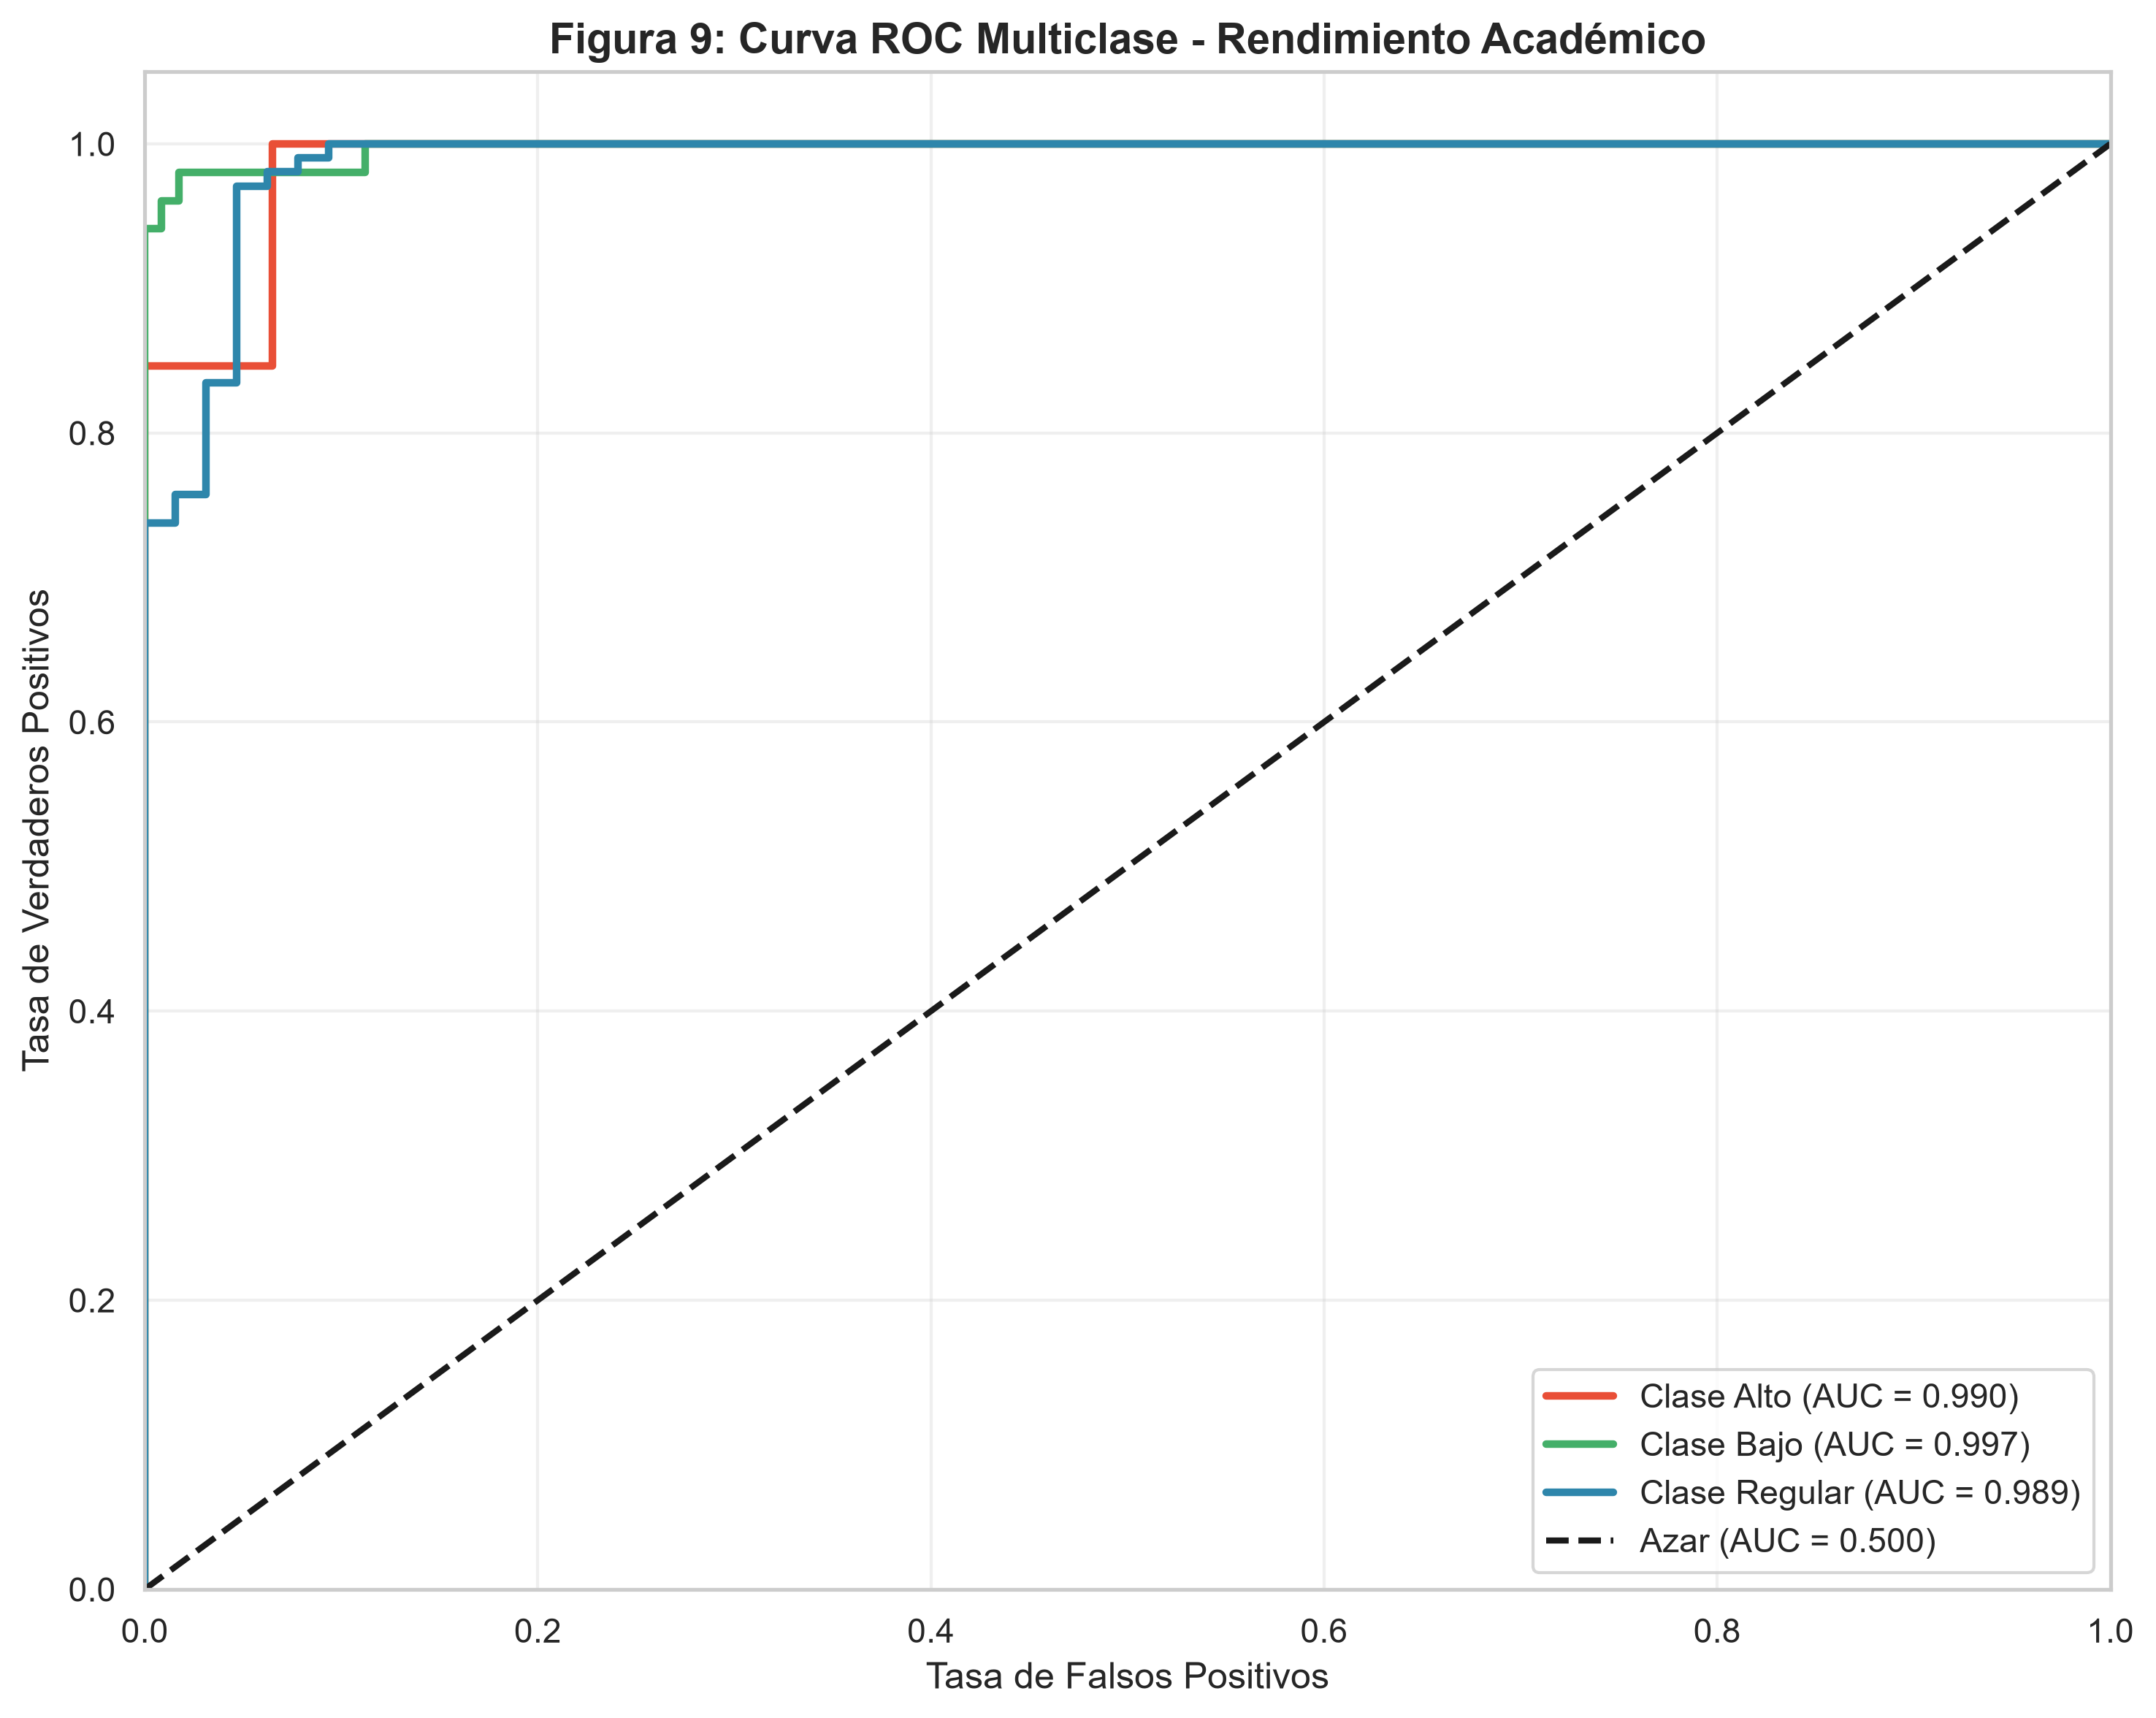

In [78]:
# ==============================================================================
# PASO 9: CURVA ROC MULTICLASE (CORREGIDO)
# ==============================================================================
print("\n[9/11] Generando Curva ROC Multiclase...")
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# 🔑 CLAVE: Obtener el orden REAL de clases del clasificador entrenado
classifier = best_pipeline.named_steps['classifier']
preprocessor = best_pipeline.named_steps['preprocessor']

# El orden de clases del clasificador (puede diferir del LabelEncoder)
classifier_classes = classifier.classes_
print(f"   • Orden de clases del clasificador: {classifier_classes}")

# Binarizar las etiquetas usando el MISMO orden que el clasificador
y_test_bin = label_binarize(y_test, classes=classifier_classes)
n_classes = y_test_bin.shape[1]

# Obtener las probabilidades predichas (ya vienen en el orden correcto del clasificador)
y_prob = best_pipeline.predict_proba(X_test)
print(f"   • Shape de y_prob: {y_prob.shape}")
print(f"   • Shape de y_test_bin: {y_test_bin.shape}")

# Verificar que las dimensiones coincidan
assert y_prob.shape[1] == n_classes, f"Mismatch: {y_prob.shape[1]} vs {n_classes}"

plt.figure(figsize=(10, 8))
colors = ['#E94F37', '#44AF69', '#2E86AB']  # Rojo (Bajo), Verde (Regular), Azul (Alto)

# Mapear nombres legibles a las clases numéricas
class_names = label_encoder.inverse_transform(classifier_classes)

for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.5,
             label=f'Clase {class_names[i]} (AUC = {roc_auc:.3f})')
    print(f"   • Clase {class_names[i]}: AUC = {roc_auc:.3f}")

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Azar (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos', fontsize=12)
plt.title('Figura 9: Curva ROC Multiclase - Rendimiento Académico', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figura_09_curva_roc_multiclase_v3.png', dpi=300, bbox_inches='tight')
plt.close()
print("   ✓ Figura 9 (Curva ROC) guardada exitosamente")

# ==============================================================================
# PASO 10: EXPLICABILIDAD LOCAL CON LIME
# ==============================================================================
print("\n[10/11] Generando explicaciones locales con LIME...")
try:
    from lime.lime_tabular import LimeTabularExplainer
    
    # Función de predicción que LIME necesita (recibe numpy array, devuelve probabilidades)
    def predict_fn(x):
        # x es un numpy array 2D. Lo convertimos a DataFrame con los nombres originales de columnas
        df_x = pd.DataFrame(x, columns=X.columns)
        return best_pipeline.predict_proba(df_x)

    # Inicializar el explorador LIME con los datos de entrenamiento originales
    explainer = LimeTabularExplainer(
        X_train.values,
        feature_names=X.columns.tolist(),
        class_names=label_encoder.classes_,
        mode='classification',
        random_state=42
    )

    # Seleccionar 3 instancias de prueba que hayan sido clasificadas CORRECTAMENTE para explicaciones claras
    correct_preds = np.where(y_pred == y_test)[0]
    np.random.seed(42)
    selected_indices = np.random.choice(correct_preds, size=min(3, len(correct_preds)), replace=False)

    for idx, instance_idx in enumerate(selected_indices):
        print(f"   • Generando explicación para la instancia #{instance_idx}...")
        
        # Explicar la instancia
        exp = explainer.explain_instance(
            X_test.values[instance_idx],
            predict_fn,
            num_features=8, # Mostrar las 8 características más influyentes
            top_labels=1
        )
        
        # 10.1 Guardar versión HTML interactiva
        html_file = f'explicacion_lime_instancia_{instance_idx}_v3.html'
        exp.save_to_file(html_file)
        
        # 10.2 Generar gráfico de barras estático (.png) para el informe
        exp_data = exp.as_list(label=exp.available_labels()[0])
        features = [item[0].replace('<=', '≤').replace('>', '>') for item in exp_data] # Limpieza de texto
        weights = [item[1] for item in exp_data]
        
        plt.figure(figsize=(11, 6))
        colors_bar = ['#44AF69' if w > 0 else '#E94F37' for w in weights] # Verde: favorece, Rojo: perjudica
        y_pos = np.arange(len(features))
        plt.barh(y_pos, weights, color=colors_bar, edgecolor='black', alpha=0.8)
        plt.yticks(y_pos, features, fontsize=10)
        plt.xlabel('Peso de la característica en la predicción', fontsize=12)
        
        true_class = label_encoder.classes_[y_test[instance_idx]]
        pred_class = label_encoder.classes_[y_pred[instance_idx]]
        plt.title(f'Figura 10.{idx+1}: Explicación LIME - Estudiante #{instance_idx}\n(Clase Real: {true_class} | Predicha: {pred_class})', 
                  fontsize=13, fontweight='bold', pad=15)
        plt.gca().invert_yaxis() # La más importante arriba
        plt.grid(axis='x', alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'figura_10_{idx+1}_lime_explicacion_v3.png', dpi=300, bbox_inches='tight')
        plt.close()
        print(f"      ✓ HTML guardado: {html_file}")
        print(f"      ✓ Gráfico guardado: figura_10_{idx+1}_lime_explicacion_v3.png")

except ImportError:
    print("   ⚠️ La librería 'lime' no está instalada. Ejecuta en tu terminal: pip install lime")
except Exception as e:
    print(f"   ⚠️ LIME falló: {e}")

# ==============================================================================
# PASO 11: RESUMEN FINAL DEL PIPELINE
# ==============================================================================
print("\n" + "="*80)
print("✅ PIPELINE DE MACHINE LEARNING COMPLETADO - v3")
print("="*80)
print("\n📋 TABLAS GENERADAS:")
print("   • tabla_05_resultados_validacion_cruzada_v3.csv")
print("   • tabla_06_reporte_clasificacion_v3.txt")
print("\n📊 FIGURAS GENERADAS:")
print("   • figura_06_matriz_confusion_v3.png")
print("   • figura_07_shap_summary_v3.png")
print("   • figura_08_shap_importance_bar_v3.png")
print("   • figura_09_curva_roc_multiclase_v3.png")
print("   • figura_10_1_lime_explicacion_v3.png (y variantes)")
print("   • explicacion_lime_instancia_XX_v3.html (archivos interactivos)")
print("="*80)

In [79]:
"""
================================================================================
SCRIPT ADICIONAL: ANÁLISIS DE FRECUENCIA DE CLASIFICACIÓN ACTUAL
Universidad Nacional de Moquegua - Ingeniería de Minas
Periodo: 2020-2025
================================================================================
"""
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("ANÁLISIS DE FRECUENCIA: CLASIFICACIÓN ACTUAL")
print("="*80)

# ==============================================================================
# PASO 1: CARGA DEL DATASET
# ==============================================================================
# NOTA: Cambia el nombre del archivo si deseas usar la versión original 
# ('MINAS_2020_2025_AGGREGATED123.csv') o la fusionada/limpia.
archivo_csv = 'MINAS_LIMPIO_IMPUTADO_RIGUROSO_v3.csv'

try:
    # Se usa low_memory=False para evitar advertencias de tipos de datos mixtos
    df = pd.read_csv(archivo_csv, encoding='utf-8', low_memory=False)
    print(f"\n✅ Dataset cargado exitosamente: {df.shape[0]:,} filas × {df.shape[1]} columnas")
except FileNotFoundError:
    print(f"\n❌ ERROR: No se encontró el archivo '{archivo_csv}'.")
    print("💡 Asegúrate de que el archivo esté en la misma carpeta que este script.")
    exit()
except Exception as e:
    print(f"\n❌ ERROR al cargar el archivo: {e}")
    exit()

# ==============================================================================
# PASO 2: VALIDACIÓN DE LA COLUMNA
# ==============================================================================
columna_objetivo = 'CLASIFICACION_ACTUAL'

if columna_objetivo not in df.columns:
    print(f"\n❌ ERROR: La columna '{columna_objetivo}' no existe en el dataset.")
    print(f"💡 Columnas disponibles (primeras 10): {df.columns.tolist()[:10]}")
    exit()

# ==============================================================================
# PASO 3: CÁLCULO DE FRECUENCIA Y PORCENTAJE
# ==============================================================================
print("\n[1/2] Calculando frecuencias...")

# value_counts cuenta las ocurrencias. dropna=False incluye valores nulos si los hubiera.
conteo = df[columna_objetivo].value_counts(dropna=False).reset_index()
conteo.columns = ['Clasificación Actual', 'Frecuencia Absoluta']

# Calcular el porcentaje
total_registros = len(df)
conteo['Porcentaje (%)'] = (conteo['Frecuencia Absoluta'] / total_registros * 100).round(2)

# Ordenar de mayor a menor frecuencia para mejor lectura
conteo = conteo.sort_values(by='Frecuencia Absoluta', ascending=False).reset_index(drop=True)

# Agregar fila de TOTAL (muy útil para tablas de tesis)
fila_total = pd.DataFrame({
    'Clasificación Actual': ['TOTAL GENERAL'],
    'Frecuencia Absoluta': [total_registros],
    'Porcentaje (%)': [100.00]
})
resultado_final = pd.concat([conteo, fila_total], ignore_index=True)

# ==============================================================================
# PASO 4: VISUALIZACIÓN Y EXPORTACIÓN
# ==============================================================================
print("\n[2/2] Generando tabla resumen...")
print("\n" + "="*80)
print(f"TABLA: DISTRIBUCIÓN DE ESTUDIANTES POR {columna_objetivo.upper()}")
print("="*80)

# Formatear la salida para que se vea limpia en la consola
print(resultado_final.to_string(index=False))
print("="*80)

# Guardar en CSV para insertar fácilmente en Word/Excel
nombre_salida = 'tabla_frecuencia_clasificacion_actual.csv'
resultado_final.to_csv(nombre_salida, index=False, encoding='utf-8')
print(f"\n✅ Tabla guardada exitosamente como: '{nombre_salida}'")
print("💡 Puedes abrir este archivo en Excel para darle formato de tabla APA 7ª ed.")

ANÁLISIS DE FRECUENCIA: CLASIFICACIÓN ACTUAL

✅ Dataset cargado exitosamente: 833 filas × 125 columnas

[1/2] Calculando frecuencias...

[2/2] Generando tabla resumen...

TABLA: DISTRIBUCIÓN DE ESTUDIANTES POR CLASIFICACION_ACTUAL
Clasificación Actual  Frecuencia Absoluta  Porcentaje (%)
            EGRESADO                  318           38.18
          ESTUDIANTE                  310           37.21
          SANCIONADO                   54            6.48
              RETIRO                   47            5.64
            ABANDONO                   37            4.44
            RENUNCIA                   28            3.36
       SIN MATRICULA                   26            3.12
             RESERVA                    7            0.84
       RETIRORESERVA                    6            0.72
       TOTAL GENERAL                  833          100.00

✅ Tabla guardada exitosamente como: 'tabla_frecuencia_clasificacion_actual.csv'
💡 Puedes abrir este archivo en Excel para darle fo

In [80]:
"""
================================================================================
SCRIPT ADICIONAL: ANÁLISIS DE FRECUENCIA DE CLASIFICACIÓN ACTUAL
Universidad Nacional de Moquegua - Ingeniería de Minas
Periodo: 2020-2025
================================================================================
"""
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("ANÁLISIS DE FRECUENCIA: CLASIFICACIÓN ACTUAL")
print("="*80)

# ==============================================================================
# PASO 1: CARGA DEL DATASET
# ==============================================================================
# NOTA: Cambia el nombre del archivo si deseas usar la versión original 
# ('MINAS_2020_2025_AGGREGATED123.csv') o la fusionada/limpia.
archivo_csv = 'MINAS_LIMPIO_IMPUTADO_RIGUROSO_v3.csv'

try:
    # Se usa low_memory=False para evitar advertencias de tipos de datos mixtos
    df = pd.read_csv(archivo_csv, encoding='utf-8', low_memory=False)
    print(f"\n✅ Dataset cargado exitosamente: {df.shape[0]:,} filas × {df.shape[1]} columnas")
except FileNotFoundError:
    print(f"\n❌ ERROR: No se encontró el archivo '{archivo_csv}'.")
    print("💡 Asegúrate de que el archivo esté en la misma carpeta que este script.")
    exit()
except Exception as e:
    print(f"\n❌ ERROR al cargar el archivo: {e}")
    exit()

# ==============================================================================
# PASO 2: VALIDACIÓN DE LA COLUMNA
# ==============================================================================
columna_objetivo = 'CLASIFICACION_ACTUAL'

if columna_objetivo not in df.columns:
    print(f"\n❌ ERROR: La columna '{columna_objetivo}' no existe en el dataset.")
    print(f"💡 Columnas disponibles (primeras 10): {df.columns.tolist()[:10]}")
    exit()

# ==============================================================================
# PASO 3: CÁLCULO DE FRECUENCIA Y PORCENTAJE
# ==============================================================================
print("\n[1/2] Calculando frecuencias...")

# value_counts cuenta las ocurrencias. dropna=False incluye valores nulos si los hubiera.
conteo = df[columna_objetivo].value_counts(dropna=False).reset_index()
conteo.columns = ['Clasificación Actual', 'Frecuencia Absoluta']

# Calcular el porcentaje
total_registros = len(df)
conteo['Porcentaje (%)'] = (conteo['Frecuencia Absoluta'] / total_registros * 100).round(2)

# Ordenar de mayor a menor frecuencia para mejor lectura
conteo = conteo.sort_values(by='Frecuencia Absoluta', ascending=False).reset_index(drop=True)

# Agregar fila de TOTAL (muy útil para tablas de tesis)
fila_total = pd.DataFrame({
    'Clasificación Actual': ['TOTAL GENERAL'],
    'Frecuencia Absoluta': [total_registros],
    'Porcentaje (%)': [100.00]
})
resultado_final = pd.concat([conteo, fila_total], ignore_index=True)

# ==============================================================================
# PASO 4: VISUALIZACIÓN Y EXPORTACIÓN
# ==============================================================================
print("\n[2/2] Generando tabla resumen...")
print("\n" + "="*80)
print(f"TABLA: DISTRIBUCIÓN DE ESTUDIANTES POR {columna_objetivo.upper()}")
print("="*80)

# Formatear la salida para que se vea limpia en la consola
print(resultado_final.to_string(index=False))
print("="*80)

# Guardar en CSV para insertar fácilmente en Word/Excel
nombre_salida = 'tabla_frecuencia_clasificacion_actual.csv'
resultado_final.to_csv(nombre_salida, index=False, encoding='utf-8')
print(f"\n✅ Tabla guardada exitosamente como: '{nombre_salida}'")
print("💡 Puedes abrir este archivo en Excel para darle formato de tabla APA 7ª ed.")

ANÁLISIS DE FRECUENCIA: CLASIFICACIÓN ACTUAL

✅ Dataset cargado exitosamente: 833 filas × 125 columnas

[1/2] Calculando frecuencias...

[2/2] Generando tabla resumen...

TABLA: DISTRIBUCIÓN DE ESTUDIANTES POR CLASIFICACION_ACTUAL
Clasificación Actual  Frecuencia Absoluta  Porcentaje (%)
            EGRESADO                  318           38.18
          ESTUDIANTE                  310           37.21
          SANCIONADO                   54            6.48
              RETIRO                   47            5.64
            ABANDONO                   37            4.44
            RENUNCIA                   28            3.36
       SIN MATRICULA                   26            3.12
             RESERVA                    7            0.84
       RETIRORESERVA                    6            0.72
       TOTAL GENERAL                  833          100.00

✅ Tabla guardada exitosamente como: 'tabla_frecuencia_clasificacion_actual.csv'
💡 Puedes abrir este archivo en Excel para darle fo

In [81]:
import pandas as pd

# Cargar el dataset final limpio
df = pd.read_csv('MINAS_LIMPIO_IMPUTADO_RIGUROSO_v3.csv', encoding='utf-8', low_memory=False)

# Palabras clave para buscar en los nombres de las columnas
keywords = ['INGRESO', 'PADRE', 'MADRE', 'VIVIENDA', 'PARED', 'TECHO', 'PISO', 
            'INTERNET', 'COMPUTADORA', 'EDUCATIVO', 'INSTRUCCION', 'TRABAJO', 'LABORAL', 'HIJOS']

# Filtrar columnas que contengan alguna de estas palabras (insensible a mayúsculas/minúsculas)
cols_socio = [col for col in df.columns if any(keyword in col.upper() for keyword in keywords)]

print("="*80)
print("VARIABLES SOCIOECONÓMICAS Y PERSONALES REALES EN EL DATASET")
print("="*80)
if cols_socio:
    for i, col in enumerate(sorted(cols_socio), 1):
        # Mostrar un ejemplo de los valores únicos para que identifiques la variable
        ejemplos = df[col].dropna().unique()[:3] 
        print(f"{i:02d}. {col:<35} | Ejemplos: {ejemplos}")
else:
    print("⚠️ No se encontraron columnas con estas palabras clave.")
print("="*80)

VARIABLES SOCIOECONÓMICAS Y PERSONALES REALES EN EL DATASET
01. ACUDE_MADRE                         | Ejemplos: <StringArray>
['NO', 'Si']
Length: 2, dtype: str
02. ACUDE_PADRE                         | Ejemplos: <StringArray>
['NO', 'Si']
Length: 2, dtype: str
03. COMPUTADORA                         | Ejemplos: <StringArray>
['SI', 'NO']
Length: 2, dtype: str
04. ESTADO_CIVIL_PADRES                 | Ejemplos: <StringArray>
['Casados', 'Convivientes', 'Separados']
Length: 3, dtype: str
05. ESTADO_VIVIENDA                     | Ejemplos: <StringArray>
['Totalmente construida', 'Enconstruccion', 'Vivienda improvisada']
Length: 3, dtype: str
06. INGRESO_FAMILIAR                    | Ejemplos: <StringArray>
[ 'De S/. 951.00 a S/. 1500.00',          'Menos de S/. 950.00',
 'De S/. 1501.00 a S/. 2500.00']
Length: 3, dtype: str
07. INTERNET                            | Ejemplos: <StringArray>
['SI', 'NO']
Length: 2, dtype: str
08. MADRE_VIVA                          | Ejemplos: <StringArray>